# 3. Network analysis

This notebook analyses the network built in `02_build_network.ipynb`: degree distribution, connected components, paths, clustering and density, centrality, and degree assortativity. The network is analysed in its simple, undirected, unweighted version: one edge per pair of organisations that share at least one project, weights ignored.

**Reference models.** Every statistic is compared with the same statistic on two synthetic networks of (almost) the same size: an **Erdős–Rényi** graph with the same $N$ and $L$, and a **Barabási–Albert** graph with the same $N$, grown by preferential attachment with $m = L / N$ links per new node, rounded to the nearest integer.

**Computation.** All the measures are computed with `igraph`. Path-based measures and centralities are computed on the giant component of each network: distances are not defined between disconnected nodes, and this way all the centralities refer to the same set of nodes.

## Imports and configuration

In [1]:
import random
from pathlib import Path

import igraph as ig
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import powerlaw
from scipy.stats import spearmanr

# Network built in 02_build_network.ipynb
NET_DIR = Path("../data/network")
# Output folder for the figures
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Random seed, so that the two reference models are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# One colour per network, used in every figure
COLORS = {"CORDIS": "#1f4e79", "ER": "#c0504d", "BA": "#7f9c3a"}

## Building the network and the reference models

We build the simple undirected graph with all the organisations as vertices, isolated ones included, and generate the two reference models. 

In [2]:
nodes = pd.read_csv(NET_DIR / "nodes.csv.gz", keep_default_na=False, na_values=[""])
edges = pd.read_csv(NET_DIR / "edges.csv.gz")

# Since igraph numbers the vertices from 0 to N-1, map each organisation id to its position in the node table,
# and the edge list is rewritten with these numbers
index = {org_id: i for i, org_id in enumerate(nodes["id"])}
edge_list = list(zip(edges["source"].map(index), edges["target"].map(index)))

# Build the simple undirected unweighted graph: all organisations as vertices, one edge per linked pair, no weight
G = ig.Graph(n=len(nodes), edges=edge_list, directed=False)

# Attach the attributes used later in the rankings, in the same order as the vertices
G.vs["name"] = nodes["name"].tolist()
G.vs["country"] = nodes["country"].tolist()
G.vs["activityType"] = nodes["activityType"].tolist()

# Size of the network
N, L = G.vcount(), G.ecount()
print(f"CORDIS network: {N} nodes, {L} edges, simple: {G.is_simple()}")

CORDIS network: 35200 nodes, 1061382 edges, simple: True


In [3]:
# ER graph
ER = ig.Graph.Erdos_Renyi(n=N, m=L)

# BA graph (m = L / N rounded to the nearest integer)
m = round(L / N)
BA = ig.Graph.Barabasi(n=N, m=m)

# The three networks, in the order used in every table and figure
networks = {"CORDIS": G, "ER": ER, "BA": BA}

# Size of each network: nodes, edges and average degree <k> = 2L / N
print(f"{'network':8} {'nodes':>8} {'edges':>10} {'<k>':>7}")
for name, g in networks.items():
    print(f"{name:8} {g.vcount():>8} {g.ecount():>10} {2 * g.ecount() / g.vcount():>7.1f}")

# Parameters of the two models
print(f"\nER edge probability p = {L / (N * (N - 1) / 2):.5f};  BA parameter m = {m}")

network     nodes      edges     <k>
CORDIS      35200    1061382    60.3
ER          35200    1061382    60.3
BA          35200    1055535    60.0

ER edge probability p = 0.00171;  BA parameter m = 30


The BA graph has slightly fewer edges than CORDIS, because each new node brings $m = 30$ links, while the exact ratio $L / N$ is 30.15.

## Degree distribution

We compare the three distributions on log-log axes, both as $P(k)$ and as the complementary cumulative distribution $P(K \geq k)$, which is less noisy in the tail. The expected shapes are a Poisson distribution centred on $\langle k \rangle$ for ER and a power law $P(k) \sim k^{-3}$ for BA.

In [4]:
# Degree of every node, one array per network
degrees = {name: np.array(g.degree()) for name, g in networks.items()}

# Average, median and maximum degree, and number of nodes without edges
print(f"{'network':8} {'<k>':>7} {'median':>7} {'max':>7} {'k = 0':>7}")
for name, k in degrees.items():
    print(f"{name:8} {k.mean():>7.1f} {np.median(k):>7.0f} {k.max():>7} {(k == 0).sum():>7}")

network      <k>  median     max   k = 0
CORDIS      60.3      23    6796     818
ER          60.3      60      95       0
BA          60.0      42    1489       0


With the same average degree, CORDIS has the lowest median and the highest maximum: its links are concentrated on a few very connected organisations, more than in BA.

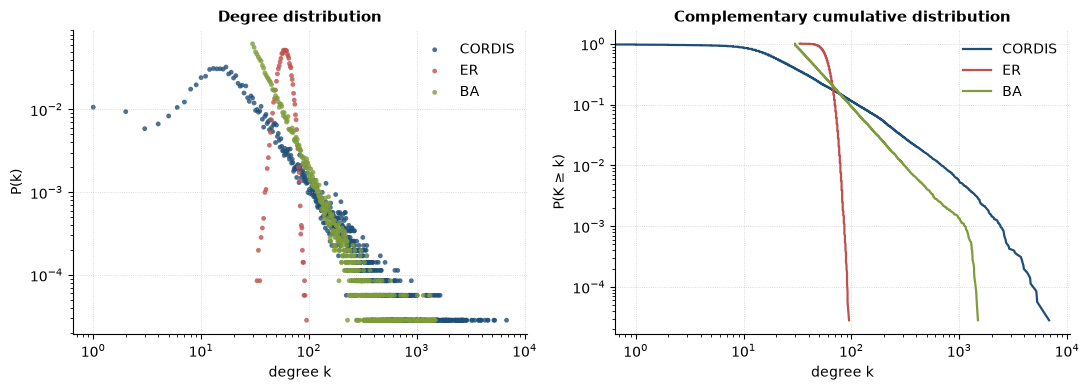

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, k in degrees.items():
    # Left panel, P(k): for each degree value, the fraction of nodes that have it
    values, counts = np.unique(k, return_counts=True)
    axes[0].scatter(values, counts / len(k), s=12, alpha=0.8, color=COLORS[name], edgecolor="none", label=name)
    # Right panel, P(K >= k): complementary cumulative distribution, fraction of nodes with degree >= k
    k_sorted = np.sort(k)
    ccdf = 1 - np.arange(len(k_sorted)) / len(k_sorted)
    axes[1].plot(k_sorted, ccdf, color=COLORS[name], lw=1.6, label=name)

for ax, ylabel, title in zip(axes, ["P(k)", "P(K ≥ k)"], ["Degree distribution", "Complementary cumulative distribution"]):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("degree k")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "degree_distribution.png", dpi=200)
plt.show()

The two reference models have the expected shapes: ER is a narrow peak around $\langle k \rangle$, and BA a straight line starting at $k = m$. The tail of CORDIS decreases more slowly than the BA one on the cumulative plot, which confirms that its large hubs are more frequent than in BA.

### Power-law fit

The tail of CORDIS looks like a straight line, as in a power law. To check it, we use the `powerlaw` package to find where the power law starts ($x_{min}$) and how steep it is ($\alpha$). The fit is repeated on the BA graph, whose exponent is known to be 3, as a check. A log-normal tail looks like a straight line too, so for CORDIS we also test which of the two fits better: the log-likelihood ratio $R$ is negative when the log-normal fits better.

In [6]:
# Power-law fit of the tail of the degree distribution, for CORDIS and for the BA check
print(f"{'network':8} {'alpha':>7} {'xmin':>6} {'nodes in the tail':>19}")
fits = {}
for name in ["CORDIS", "BA"]:

    # Degrees of the nodes with at least one edge (a power law is defined for k > 0)
    k = degrees[name][degrees[name] > 0]

    # Fit: xmin = degree from which the power law holds, alpha = exponent estimated on k >= xmin
    fits[name] = powerlaw.Fit(k, discrete=True, verbose=False)
    xmin = fits[name].power_law.xmin
    tail = (k >= xmin).sum()

    print(f"{name:8} {fits[name].power_law.alpha:>7.2f} {xmin:>6.0f} {tail:>11} ({tail / len(k):.1%})")

# Comparison with a log-normal fit on the tail of CORDIS: R < 0 favours the log-normal, p = significance
R, p = fits["CORDIS"].distribution_compare("power_law", "lognormal")
print(f"\nCORDIS, power law against log-normal: R = {R:.2f}, p = {p:.3f}")

network    alpha   xmin   nodes in the tail
CORDIS      2.40    172        2261 (6.6%)
BA          2.96     42       18339 (52.1%)

CORDIS, power law against log-normal: R = -9.37, p = 0.004


On BA the fit gives 2.96, close to the theoretical 3, and covers more than half of the nodes. On CORDIS the exponent is 2.40, but the power law holds only for 6.6% of the nodes, and even there the log-normal fits better ($R < 0$). The distribution is therefore heavy-tailed, with larger hubs than BA, but not a power law in the strict sense.

## Connected components

We count the connected components of the three networks and the size of the largest one. Both reference models are expected to have a single component: ER because its average degree is above $\ln N$, the threshold of the connected regime, and BA because every new node is attached to nodes already in the graph.

In [7]:
# Connected components of each network, and the largest one (giant component) as a separate graph,
# used later for the path-based measures and the centralities
components = {name: g.connected_components() for name, g in networks.items()}
giants = {name: comp.giant() for name, comp in components.items()}

# Number of components, components of a single node, size of the giant component and its fraction of the nodes
print(f"{'network':8} {'components':>11} {'isolated':>9} {'giant':>8} {'fraction':>9}")
for name, comp in components.items():
    sizes = np.array(comp.sizes())
    print(f"{name:8} {len(sizes):>11} {(sizes == 1).sum():>9} {sizes.max():>8} {sizes.max() / networks[name].vcount():>7.1%}")

network   components  isolated    giant  fraction
CORDIS           864       818    34271   97.4%
ER                 1         0    35200  100.0%
BA                 1         0    35200  100.0%


CORDIS is the only network that is not connected. Besides the giant component, with 97.4% of the organisations, it has 818 isolated organisations and 45 small components. Both reference models have a single component, as expected.

## Path analysis

We compute the distribution of the distances between all pairs of nodes of the giant component, and from it the average path length $\langle d \rangle$ and the diameter. In a random network the average path length is of the order of $\ln N / \ln \langle k \rangle$, and in BA it grows even more slowly with $N$, as $\ln N / \ln \ln N$.

In [8]:
paths = {}
for name, giant in giants.items():

    # Shortest path between every pair of nodes, returned as a histogram
    hist = giant.path_length_hist(directed=False)
    lengths = np.array([int(lo) for lo, hi, count in hist.bins()])   # distances
    counts = np.array([count for lo, hi, count in hist.bins()])       # pairs of nodes at each distance

    paths[name] = {
        "distribution": counts / counts.sum(),            # fraction of pairs at each distance
        "mean": (lengths * counts).sum() / counts.sum(),  # average distance <d>
        "diameter": lengths[counts > 0].max(),            # diameter: the largest distance between two nodes
    }

# For each network: average distance and diameter
print(f"{'network':8} {'<d>':>6} {'diameter':>9}")
for name in networks:
    print(f"{name:8} {paths[name]['mean']:>6.2f} {paths[name]['diameter']:>9}")

network     <d>  diameter
CORDIS     2.72         6
ER         2.90         4
BA         2.82         4


CORDIS has the shortest average distance and the largest diameter of the three. The first is consistent with its hubs, which bring most pairs of organisations within two or three steps. The second shows that a few pairs remain farther apart than any pair of nodes in ER and BA.

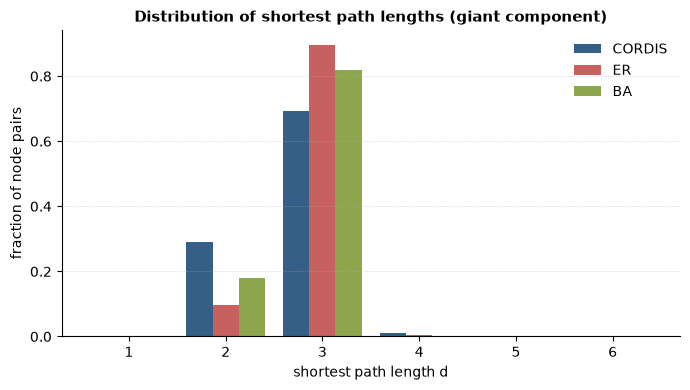

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
width = 0.27
max_d = max(len(p["distribution"]) for p in paths.values())
for i, (name, p) in enumerate(paths.items()):
    distribution = np.pad(p["distribution"], (0, max_d - len(p["distribution"])))
    ax.bar(np.arange(1, max_d + 1) + (i - 1) * width, distribution, width=width, color=COLORS[name], alpha=0.9, label=name)
ax.set_xticks(np.arange(1, max_d + 1))
ax.set_xlabel("shortest path length d")
ax.set_ylabel("fraction of node pairs")
ax.set_title("Distribution of shortest path lengths (giant component)", fontsize=11, fontweight="bold")
ax.grid(True, axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "path_length_distribution.png", dpi=200)
plt.show()

## Clustering and density

We report the density, the average clustering coefficient (nodes with fewer than two neighbours count as zero) and the transitivity, i.e. the fraction of closed triplets in the whole network. Both reference models are expected to have a low clustering coefficient: in ER it equals the density, $C = p$, and in BA it is higher but decreases with the size of the network.

In [10]:
# Local clustering coefficient of every node, one array per network (nodes with fewer than two neighbours count as zero)
local_clustering = {name: np.array(g.transitivity_local_undirected(mode="zero")) for name, g in networks.items()}

# Density, average clustering coefficient and transitivity of each network
print(f"{'network':8} {'density':>9} {'avg clustering':>15} {'transitivity':>13}")
for name, g in networks.items():
    print(f"{name:8} {g.density():>9.5f} {local_clustering[name].mean():>15.4f} {g.transitivity_undirected():>13.4f}")

network    density  avg clustering  transitivity
CORDIS     0.00171          0.7807        0.1273
ER         0.00171          0.0017        0.0017
BA         0.00170          0.0093        0.0095


The clustering coefficient of ER equals its density, as expected, while that of CORDIS is orders of magnitude higher. Its transitivity is much lower than its average clustering coefficient: the two measures weigh the nodes differently, the average giving the same weight to every node and the transitivity more weight to the high-degree ones.

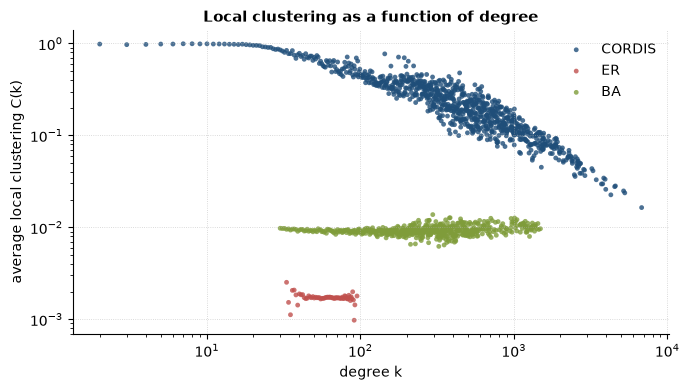

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
for name in networks:
    # Average local clustering of the nodes with degree k, for k >= 2 (clustering is defined only from degree 2)
    k, c = degrees[name], local_clustering[name]
    mask = k >= 2
    ck = pd.Series(c[mask]).groupby(k[mask]).mean()
    ax.scatter(ck.index, ck.values, s=12, alpha=0.8, color=COLORS[name], edgecolor="none", label=name)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("degree k")
ax.set_ylabel("average local clustering C(k)")
ax.set_title("Local clustering as a function of degree", fontsize=11, fontweight="bold")
ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "clustering_vs_degree.png", dpi=200)
plt.show()

In CORDIS the clustering coefficient decreases with degree, which explains the gap between its average clustering coefficient and its transitivity. The values close to 1 at low degree follow from the construction, since each project links all its participants to each other: the comparison with ER and BA cannot separate this effect from a real tendency of organisations to collaborate with the partners of their partners.

## Centrality

We compute six centrality measures on the giant component of each network: degree, closeness, harmonic, betweenness, PageRank and eigenvector centrality. For CORDIS we list the ten most central organisations by each measure. For the three networks we compare how concentrated betweenness, PageRank and eigenvector centrality are in the top 1% of nodes, and how strongly each of them correlates with degree.

In [12]:
# Six centrality measures on the giant component of each network
centrality = {}
for name, giant in giants.items():
    centrality[name] = pd.DataFrame({
        "degree": giant.degree(),
        "closeness": giant.closeness(),
        "harmonic": giant.harmonic_centrality(),
        "betweenness": giant.betweenness(),
        "pagerank": giant.pagerank(),
        "eigenvector": giant.eigenvector_centrality(),
    })

# Attributes of the organisations in the giant component, for the rankings
centrality["CORDIS"]["name"] = giants["CORDIS"].vs["name"]
centrality["CORDIS"]["country"] = giants["CORDIS"].vs["country"]
centrality["CORDIS"]["activityType"] = giants["CORDIS"].vs["activityType"]

In [13]:
measures = ["degree", "closeness", "harmonic", "betweenness", "pagerank", "eigenvector"]

# Centrality table of the CORDIS giant component: one row per organisation
top = centrality["CORDIS"]

for measure in measures:
    print(f"\nTop 10 by {measure}")

    # The ten organisations with the highest value of this measure
    ranked = top.sort_values(measure, ascending=False).head(10)

    # One line per organisation: name, country, activity type, value
    for _, row in ranked.iterrows():
        print(f"  {row['name'][:45]:45} {row['country']:>3} {row['activityType']:>4} {row[measure]:>12.4g}")


Top 10 by degree
  FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DER ANG  DE  REC         6796
  AGENCIA ESTATAL CONSEJO SUPERIOR DE INVESTIGA  ES  REC         5278
  CENTRE NATIONAL DE LA RECHERCHE SCIENTIFIQUE   FR  REC         5183
  CONSIGLIO NAZIONALE DELLE RICERCHE             IT  REC         4586
  KATHOLIEKE UNIVERSITEIT LEUVEN                 BE  HES         4535
  ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS ANAP  EL  REC         4282
  TECHNISCHE UNIVERSITEIT DELFT                  NL  HES         3967
  DANMARKS TEKNISKE UNIVERSITET                  DK  HES         3929
  COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX ENER  FR  REC         3848
  TEKNOLOGIAN TUTKIMUSKESKUS VTT OY              FI  REC         3791

Top 10 by closeness
  FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DER ANG  DE  REC        0.553
  AGENCIA ESTATAL CONSEJO SUPERIOR DE INVESTIGA  ES  REC       0.5399
  CENTRE NATIONAL DE LA RECHERCHE SCIENTIFIQUE   FR  REC       0.5385
  CONSIGLIO NAZIONALE DELLE RICERCHE             IT

The six rankings largely coincide: 13 organisations fill the six top-10 lists and Fraunhofer is first in all of them, so at the top of the network the different notions of centrality identify the same actors. All 13 are research centres or universities, although private companies are 58% of the organisations (see `02_build_network.ipynb`). Fraunhofer's lead is largest in betweenness, where its value is 1.7 times the second, against 1.3 for degree.

In [14]:
print(f"{'network':8} {'measure':12} {'top 1% share':>13} {'rho with degree':>16}")
for name, table in centrality.items():
    for measure in ["betweenness", "pagerank", "eigenvector"]:

        # Values of the measure sorted from the largest to the smallest
        values = np.sort(table[measure].values)[::-1]

        # Concentration: fraction of the total held by the top 1% of nodes
        share = values[: len(values) // 100].sum() / values.sum()

        # Spearman rank correlation between the measure and degree
        rho = spearmanr(table["degree"], table[measure]).correlation

        print(f"{name:8} {measure:12} {share:>13.1%} {rho:>16.2f}")

network  measure       top 1% share  rho with degree


CORDIS   betweenness          73.9%             0.74
CORDIS   pagerank             19.2%             0.97
CORDIS   eigenvector          18.5%             0.86
ER       betweenness           1.8%             1.00
ER       pagerank              1.3%             1.00
ER       eigenvector           1.4%             0.99
BA       betweenness          47.0%             0.96
BA       pagerank              8.2%             1.00
BA       eigenvector          10.0%             0.80


Centrality is evenly spread in ER, concentrated in BA and even more in CORDIS, on all three measures: the top 1% of organisations holds almost three quarters of the betweenness. In CORDIS betweenness is also the measure that departs most from degree (rho = 0.74, against 0.96 in BA and 1.00 in ER). This may partly follow from the construction: an organisation whose partners are all linked to each other lies on no shortest path.

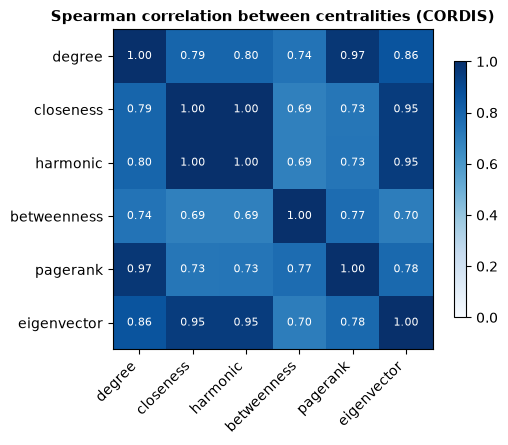

In [15]:
# Spearman rank correlation between each pair of centrality measures
corr = centrality["CORDIS"][measures].corr(method="spearman")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(measures)), measures, rotation=45, ha="right")
ax.set_yticks(range(len(measures)), measures)
for i in range(len(measures)):
    for j in range(len(measures)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if corr.values[i, j] > 0.6 else "black")
ax.set_title("Spearman correlation between centralities (CORDIS)", fontsize=11, fontweight="bold")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(FIG_DIR / "centrality_correlation.png", dpi=200)
plt.show()

Across the whole network the measures agree less than in the top-10 lists, with correlations from 0.69 to 1.00. Betweenness has the lowest correlations overall, and eigenvector centrality is closer to closeness (0.95) than to degree (0.86).

## Degree assortativity

Newman's degree assortativity $r$ is the correlation between the degrees of the two nodes at the ends of each link: positive when hubs link to hubs, negative when they link to low-degree nodes. The figure shows the average degree of the neighbours of the nodes with degree $k$, $k_{nn}(k)$, which is flat when there are no degree correlations.

network   degree assortativity
CORDIS                  -0.102
ER                       0.001
BA                       0.004


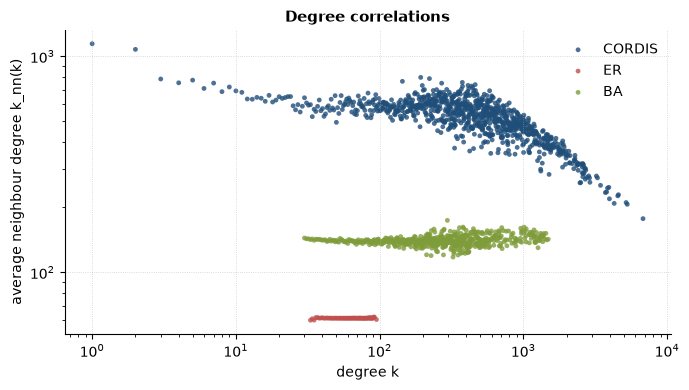

In [16]:
# Degree assortativity r of each network
print(f"{'network':8} {'degree assortativity':>21}")
for name, g in networks.items():
    print(f"{name:8} {g.assortativity_degree():>21.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
for name, g in networks.items():
    # Average degree of the neighbours of the nodes with degree k
    _, knn_k = g.knn()
    knn_k = np.array(knn_k)
    k = np.arange(1, len(knn_k) + 1)

    # Degrees that no node has are returned as NaN and are not plotted
    valid = ~np.isnan(knn_k)
    ax.scatter(k[valid], knn_k[valid], s=12, alpha=0.8, color=COLORS[name], edgecolor="none", label=name)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("degree k")
ax.set_ylabel("average neighbour degree k_nn(k)")
ax.set_title("Degree correlations", fontsize=11, fontweight="bold")
ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "degree_correlations.png", dpi=200)
plt.show()

CORDIS is disassortative ($r = -0.102$), while the two reference models show no degree correlations. The figure shows where this comes from: $k_{nn}(k)$ is roughly flat up to a few hundred partners and decreases only for the largest hubs. In a simple network with very large hubs a negative $r$ can follow from the degree sequence alone, since the hubs cannot be linked to each other often enough (structural disassortativity): the value should not be read as a tendency of hubs to avoid each other.

## Summary

All the statistics of the three networks in one table.

In [17]:
summary = pd.DataFrame({
    name: {
        "nodes": g.vcount(),
        "edges": g.ecount(),
        "average degree": round(2 * g.ecount() / g.vcount(), 1),
        "max degree": int(degrees[name].max()),
        "density": round(g.density(), 5),
        "connected components": len(components[name]),
        "giant component (share)": f"{giants[name].vcount() / g.vcount():.1%}",
        "average path length": round(paths[name]["mean"], 2),
        "diameter": int(paths[name]["diameter"]),
        "average clustering": round(local_clustering[name].mean(), 4),
        "transitivity": round(g.transitivity_undirected(), 4),
        "degree assortativity": round(g.assortativity_degree(), 3),
    }
    for name, g in networks.items()
})
summary

,CORDIS,ER,BA
nodes,35200,35200,35200
edges,1061382,1061382,1055535
average degree,60.3,60.3,60.0
max degree,6796,95,1489
density,0.00171,0.00171,0.0017
connected components,864,1,1
giant component (share),97.4%,100.0%,100.0%
average path length,2.72,2.9,2.82
diameter,6,4,4
average clustering,0.7807,0.0017,0.0093
